# Riemannian subject-identification control

## Scientific question

How strongly can covariance structure identify participants when the newest trials of every participant are held out?

## Rationale

High identity accuracy indicates stable subject-specific structure that decoding models could exploit. The control uses OAS covariance, Riemannian tangent space and balanced logistic regression.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.metrics import confusion_matrix

from br_analysis.config import ProjectPaths
from br_analysis.data import load_epoch_dataset
from br_analysis.scientific_reports import cohort_table, subject_trial_table
from br_analysis.subject_identification import run_subject_identification
from br_analysis.tasks import get_task

In [2]:
TASK_ID = "c_vs_ip"
paths = ProjectPaths.from_env("subject_identification", create_dirs=False)
task = get_task(TASK_ID)
dataset = load_epoch_dataset(paths, task, "broadband")

Selected 13160 trials from 47 subjects for c_vs_ip: c=8471, ip=4689


In [3]:
display(Markdown("## Selected task, classes and cohort"))
display(cohort_table(dataset))
display(subject_trial_table(dataset))
display({
    "pipeline": "OAS covariance -> Riemann tangent space -> standardization -> balanced logistic regression",
    "holdout": "newest 20% per subject",
    "chance_level": 1 / len(dataset.subject_ids),
})

## Selected task, classes and cohort

,class_id,label,trials,subjects,fraction
0,c,Congruent,8471,47,0.643693
1,ip,Incongruent Pure,4689,47,0.356307


class_id,subject,c,ip
0,P002,144,103
1,P003,191,193
2,P004,218,65
3,P005,166,121
4,P008,90,58
5,P009,224,121
6,P010,247,157
7,P011,121,29
8,P013,225,159
9,P014,127,69


{'pipeline': 'OAS covariance -> Riemann tangent space -> standardization -> balanced logistic regression',
 'holdout': 'newest 20% per subject',
 'chance_level': 0.02127659574468085}

## Reproducible execution

The following cell executes the complete control from the shared cached dataset; no notebook-specific preprocessing is performed.

In [4]:
result = run_subject_identification(dataset)
display({"chance_level": result.chance_level, **result.metrics.to_dict()})

{'chance_level': 0.02127659574468085,
 'accuracy': 0.9966037735849057,
 'balanced_accuracy': 0.9969114619080303,
 'f1_macro': 0.9965462267930113,
 'roc_auc': 0.9988499002101823,
 'n_samples': 2650}

## Per-subject identification and confusion diagnostics

,subject,recall
0,P002,1.000000
1,P003,1.000000
2,P004,1.000000
3,P005,1.000000
4,P008,1.000000
5,P009,1.000000
6,P010,1.000000
7,P011,1.000000
8,P013,1.000000
9,P014,1.000000


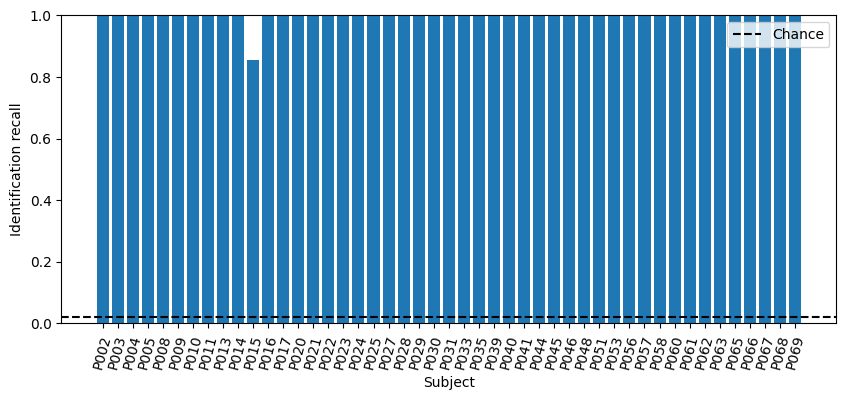

In [5]:
matrix = confusion_matrix(result.y_true, result.probabilities.argmax(axis=1), normalize="true")
subject_recall = pd.DataFrame({"subject": result.subject_ids, "recall": np.diag(matrix)})
display(subject_recall)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(subject_recall["subject"], subject_recall["recall"])
ax.axhline(result.chance_level, color="black", linestyle="--", label="Chance")
ax.set(ylabel="Identification recall", xlabel="Subject", ylim=(0, 1))
ax.tick_params(axis="x", rotation=75)
ax.legend()
plt.show()

## Interpretation, limitations and relevance to decoding

Above-chance identity confirms stable individual covariance patterns, but it does not prove leakage in a particular decoder. Compare identity strength with subject-level decoding variability and retain chronological/grouped splits for every model.